#  Projet MLOps : Prévision du Trafic Routier
Par **DHENRY Timandra** & **DE OLIVEIRA Llaora**

**Objectif :** Anticiper les pics de congestion pour aider à la régulation du trafic.

## 1. Introduction et Problématique Métier
* **Dataset :** Metro Interstate Traffic Volume (Base de données trouvé sur Kaggle).
* Voici le lien : 
 
**Problématique :** Comment anticiper les variations et les pics de trafic à partir des données historiques et météorologiques afin d'optimiser la gestion des flux routiers ?
* > **Note contextuelle :** Le jeu de données représente le trafic horaire sur l'autoroute inter-États I-94 à Minneapolis. L'objectif n'est pas seulement d'observer le trafic passé, mais de concevoir un pipeline de Machine Learning reproductible (suivi par MLflow) capable d'anticiper les variations de flux en combinant l'historique récent (lags) et les conditions exogènes (météo, calendriers).

## 2. Chargement et Nettoyage des Données
Vérification du format des dates, tri chronologique et traitement des doublons via notre module modulaire `src/clean.py`.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
from src.clean import load_and_clean_data

# Charger et nettoyer les données en remontant d'un dossier avec "../"
df = load_and_clean_data("../data/raw/Metro_Interstate_Traffic_Volume.csv")

# Afficher les 5 premières lignes
print(df.head())
print("Dimensions du dataset :", df.shape)

            date_time holiday        temp  rain_1h  snow_1h  clouds_all  \
0 2015-06-11 20:00:00    None  287.586000      0.0      0.0   92.000000   
1 2015-06-11 21:00:00    None  288.038591      0.0      0.0   87.818182   
2 2015-06-11 22:00:00    None  288.491182      0.0      0.0   83.636364   
3 2015-06-11 23:00:00    None  288.943773      0.0      0.0   79.454545   
4 2015-06-12 00:00:00    None  289.396364      0.0      0.0   75.272727   

  weather_main weather_description  traffic_volume  
0         Rain          light rain     2886.000000  
1         Rain          light rain     2953.909091  
2         Rain          light rain     3021.818182  
3         Rain          light rain     3089.727273  
4         Rain          light rain     3157.636364  
Dimensions du dataset : (28972, 9)


## 3. Analyse Descriptive (Exploratory Data Analysis)
Analyse des distributions, recherche de valeurs manquantes et mise en évidence de la saisonnalité temporelle.

--- Statistiques descriptives du volume de trafic ---
count    28630.000000
mean      3308.792379
std       1958.471367
min          0.000000
25%       1316.500000
50%       3497.000000
75%       4939.000000
max       7280.000000
Name: traffic_volume, dtype: float64

--- Valeurs manquantes par colonne ---
date_time                0
holiday                  0
temp                   342
rain_1h                342
snow_1h                342
clouds_all             342
weather_main           342
weather_description    342
traffic_volume         342
hour                     0
day                      0
month                    0
dayofweek                0
is_weekend               0
temp_c                 342
is_holiday               0
dtype: int64


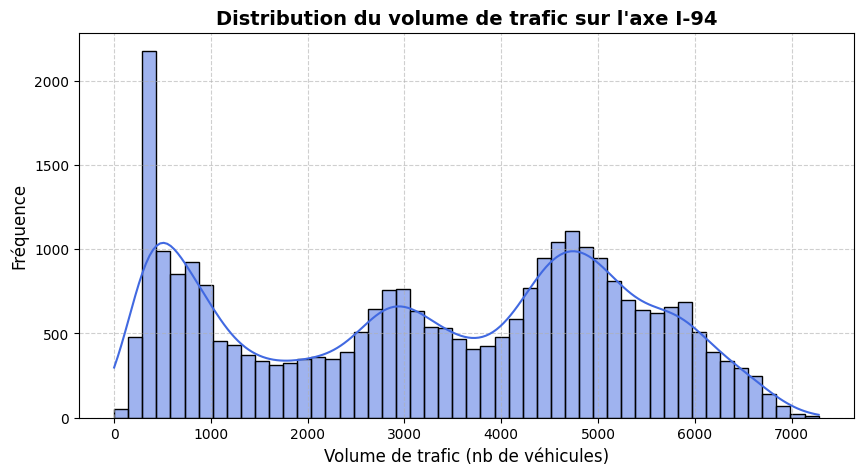

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Afficher les statistiques descriptives globales (moyenne, min, max, écart-type...)
print("--- Statistiques descriptives du volume de trafic ---")
print(df['traffic_volume'].describe())

# 2. Vérifier s'il y a des valeurs manquantes dans le dataset
print("\n--- Valeurs manquantes par colonne ---")
print(df.isnull().sum())

# 3. Visualisation de la distribution du volume de trafic
plt.figure(figsize=(10, 5))
sns.histplot(df['traffic_volume'], kde=True, bins=50, color='royalblue')
plt.title("Distribution du volume de trafic sur l'axe I-94", fontsize=14, fontweight='bold')
plt.xlabel("Volume de trafic (nb de véhicules)", fontsize=12)
plt.ylabel("Fréquence", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [7]:
from src.features import add_time_features

df = add_time_features(df)
df['temp_c'] = df['temp'] - 273.15          # Kelvin -> Celsius
df['is_holiday'] = df['holiday'] != 'None'
jours = ['Lundi', 'Mardi', 'Mercredi', 'Jeudi', 'Vendredi', 'Samedi', 'Dimanche']

### 3.1 Vue d'ensemble des variables

#### Tableaux de synthèse

In [ ]:
num_cols = ['traffic_volume', 'temp_c', 'rain_1h', 'snow_1h', 'clouds_all']
display(df[num_cols].describe().round(1))

manquantes = df.isnull().sum().to_frame('manquantes')
manquantes['%'] = (manquantes['manquantes'] / len(df) * 100).round(2)
display(manquantes[manquantes['manquantes'] > 0])

print("Période :", df['date_time'].min(), "->", df['date_time'].max())
print("Asymétrie du trafic :", round(df['traffic_volume'].skew(), 2))

,traffic_volume,temp_c,rain_1h,snow_1h,clouds_all
count,28630.0,28630.0,28630.0,28630.0,28630.0
mean,3308.8,9.6,0.1,0.0,42.1
std,1958.5,12.4,0.6,0.0,39.1
min,0.0,-29.8,0.0,0.0,0.0
25%,1316.5,0.4,0.0,0.0,1.0
50%,3497.0,11.6,0.0,0.0,40.0
75%,4939.0,19.7,0.0,0.0,90.0
max,7280.0,36.9,31.8,0.5,100.0


,manquantes,%
temp,342,1.18
rain_1h,342,1.18
snow_1h,342,1.18
clouds_all,342,1.18
weather_main,342,1.18
weather_description,342,1.18
traffic_volume,342,1.18
temp_c,342,1.18


Période : 2015-06-11 20:00:00 -> 2018-09-30 23:00:00
Asymétrie du trafic : -0.15


### 3.2 Évolution et saisonnalité

série temporelle et profils

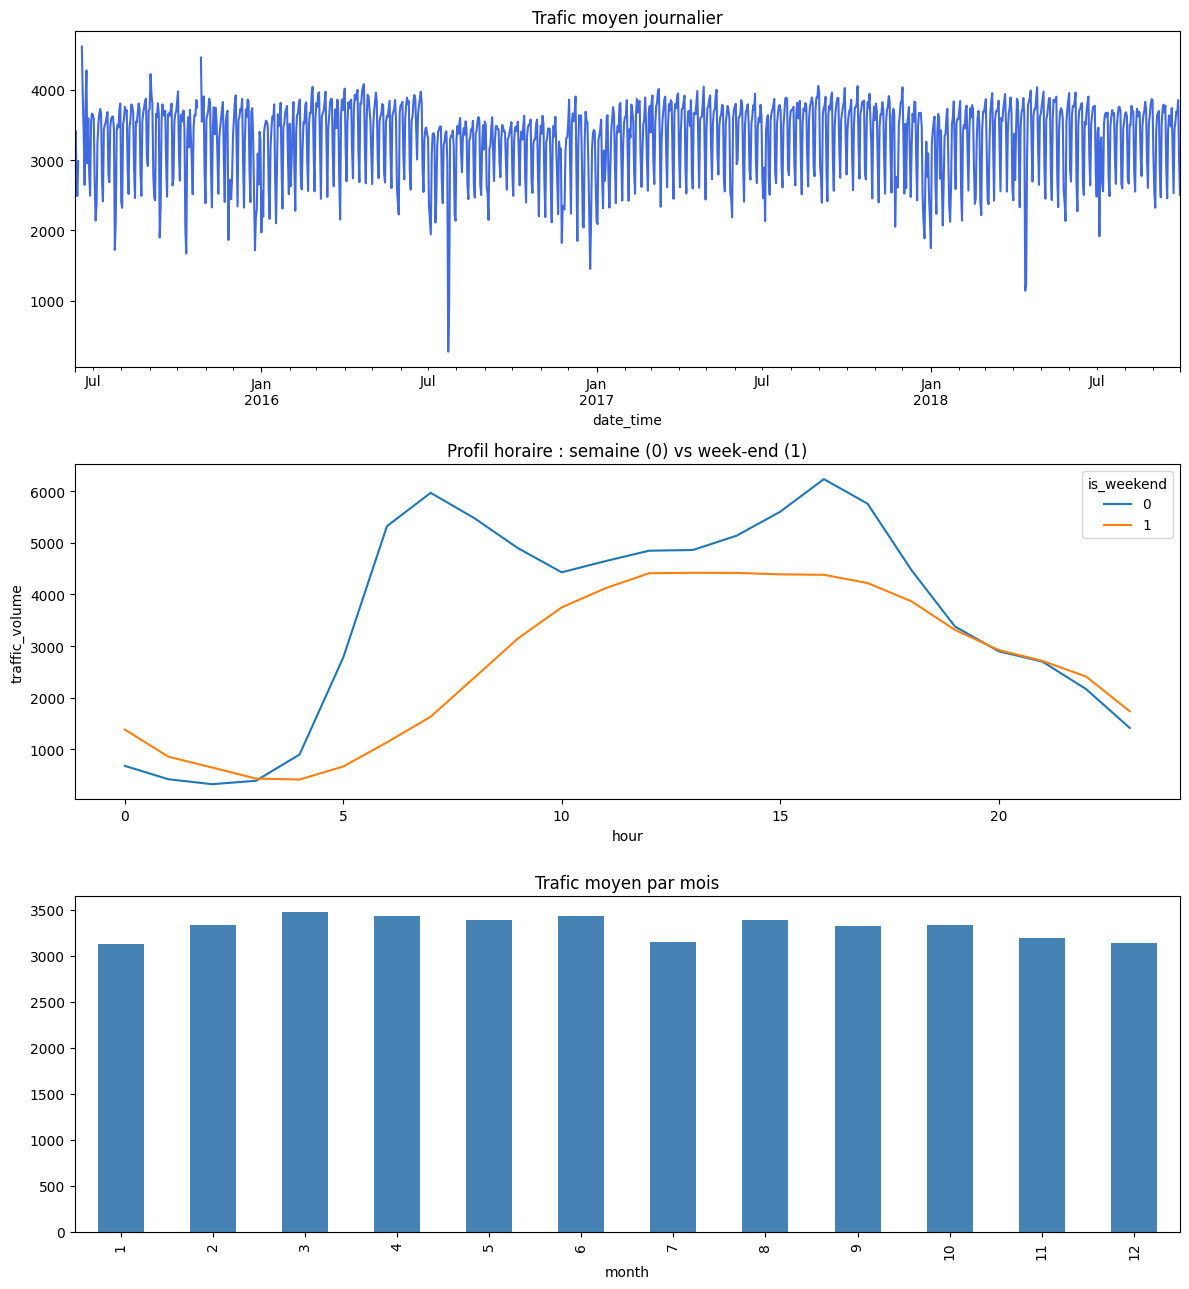

In [9]:
 fig, axes = plt.subplots(3, 1, figsize=(12, 13))

# Évolution dans le temps (moyenne journalière)
df.set_index('date_time')['traffic_volume'].resample('D').mean().plot(ax=axes[0], color='royalblue')
axes[0].set_title("Trafic moyen journalier")

# Profil par heure : semaine vs week-end
sns.lineplot(data=df, x='hour', y='traffic_volume', hue='is_weekend', errorbar=None, ax=axes[1])
axes[1].set_title("Profil horaire : semaine (0) vs week-end (1)")

# Moyenne par mois
df.groupby('month')['traffic_volume'].mean().plot(kind='bar', ax=axes[2], color='steelblue')
axes[2].set_title("Trafic moyen par mois")

plt.tight_layout()
plt.show()

heatmap jour × heure

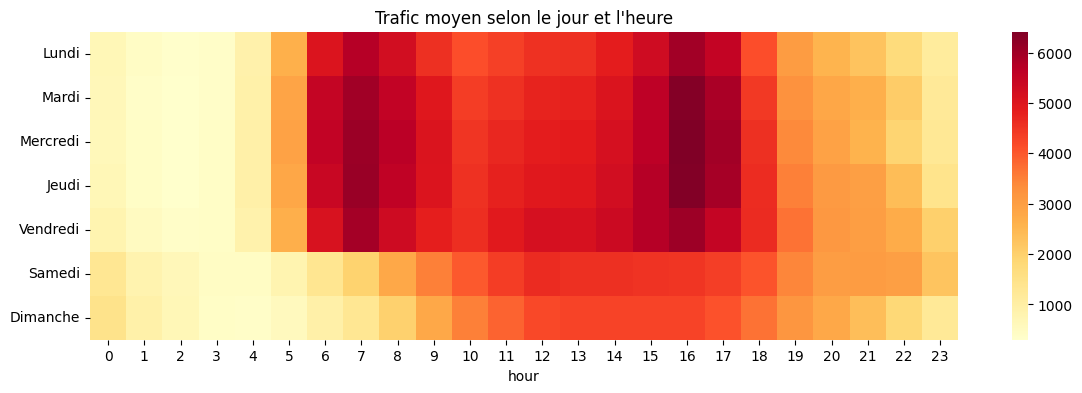

In [10]:
pv = df.pivot_table(index='dayofweek', columns='hour', values='traffic_volume', aggfunc='mean')
pv.index = jours
plt.figure(figsize=(14, 4))
sns.heatmap(pv, cmap='YlOrRd', annot=False)
plt.title("Trafic moyen selon le jour et l'heure")
plt.show()

### 3.3 Influence de la météo et des jours fériés
tableau (voir le nom que je met)

,count,mean,median,std
weather_main,,,,
Smoke,15,2560.0,2561.0,1786.0
Fog,171,2844.0,2318.0,2262.0
Mist,2417,2871.0,2696.0,2145.0
Thunderstorm,408,3051.0,3061.0,1928.0
Clear,10242,3058.0,3087.0,1960.0
Snow,1772,3085.0,3214.0,1868.0
Drizzle,447,3212.0,3153.0,2013.0
Rain,3388,3323.0,3598.0,1972.0
Haze,613,3545.0,4085.0,1855.0


,count,mean,median
is_holiday,,,
False,28595,3312.0,3502.0
True,35,880.0,812.0


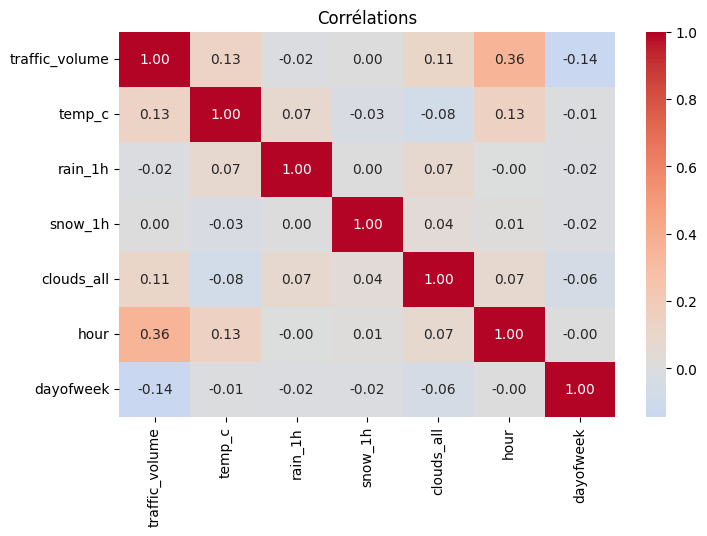

In [11]:
display(df.groupby('weather_main')['traffic_volume']
          .agg(['count', 'mean', 'median', 'std']).round(0).sort_values('mean'))

display(df.groupby('is_holiday')['traffic_volume'].agg(['count', 'mean', 'median']).round(0))

plt.figure(figsize=(8, 5))
sns.heatmap(df[num_cols + ['hour', 'dayofweek']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title("Corrélations")
plt.show()